In [1]:
import os

n_threads = "5" 
os.environ["OMP_NUM_THREADS"] = n_threads
os.environ["OPENBLAS_NUM_THREADS"] = n_threads
os.environ["MKL_NUM_THREADS"] = n_threads
os.environ["VECLIB_MAXIMUM_THREADS"] = n_threads
os.environ["NUMEXPR_NUM_THREADS"] = n_threads

import glob
import pandas as pd
import scanpy as sc
import anndata as ad
import scvelo as scv
import numpy as np
import matplotlib.pyplot as plt

scv.set_figure_params()

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['savefig.dpi'] = 300

In [2]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [3]:
os.chdir('/data_hdd4/yuseong/cancer_aging/analysis/h.github/Fig2')

### LOAD ENDOTHELIAL ADATA

In [9]:
adata = sc.read_h5ad('data/2f_h_j/patient_endo_processed.h5ad')

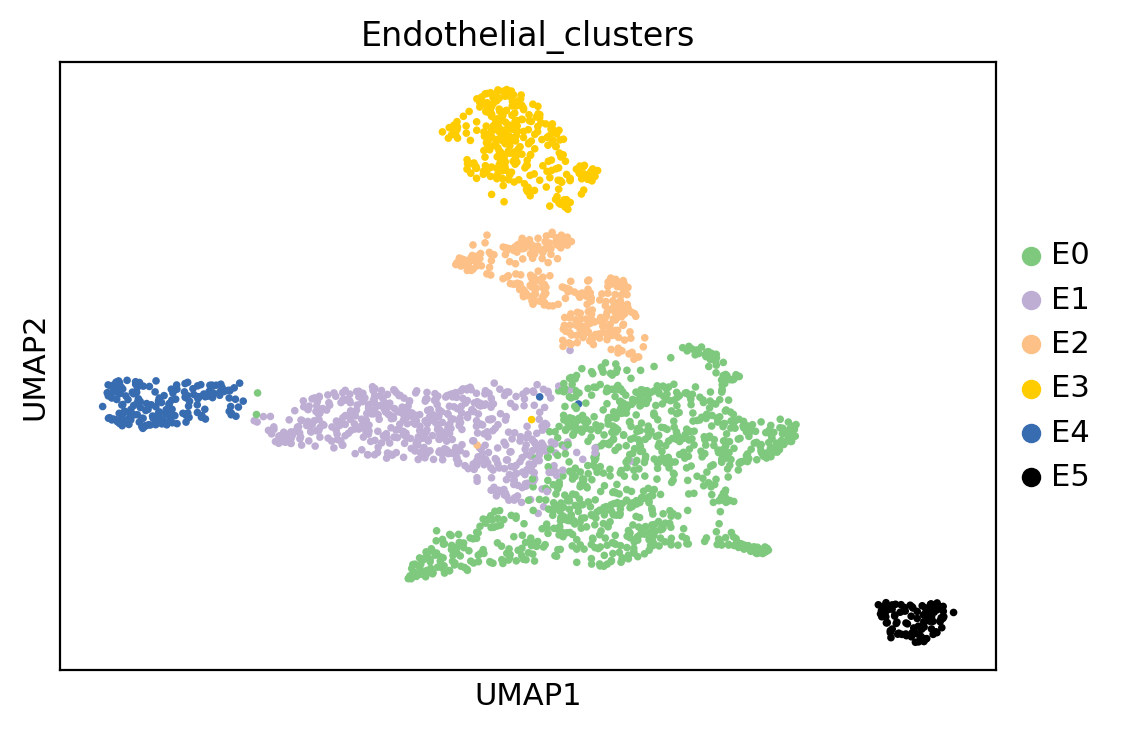

In [10]:
sc.pl.umap(adata, color = 'Endothelial_clusters', size=30)

In [ ]:
### mapping cells with endothelial sub2

In [11]:
sub_bars = pd.read_csv('data/2f_h_j/endothelial_sub2_barcodes_list.csv')
sub_bars = sub_bars.barcodes.unique().tolist()
sub_bars = [x.replace('-','.') for x in sub_bars]

adata.obs['sub_match'] = adata.obs.barcode.apply(lambda x: 'Endothelial sub2' if x in sub_bars else 'Endothelial sub1')
adata.obs.sub_match.value_counts()

sub_match
Endothelial sub1    2309
Endothelial sub2      97
Name: count, dtype: int64

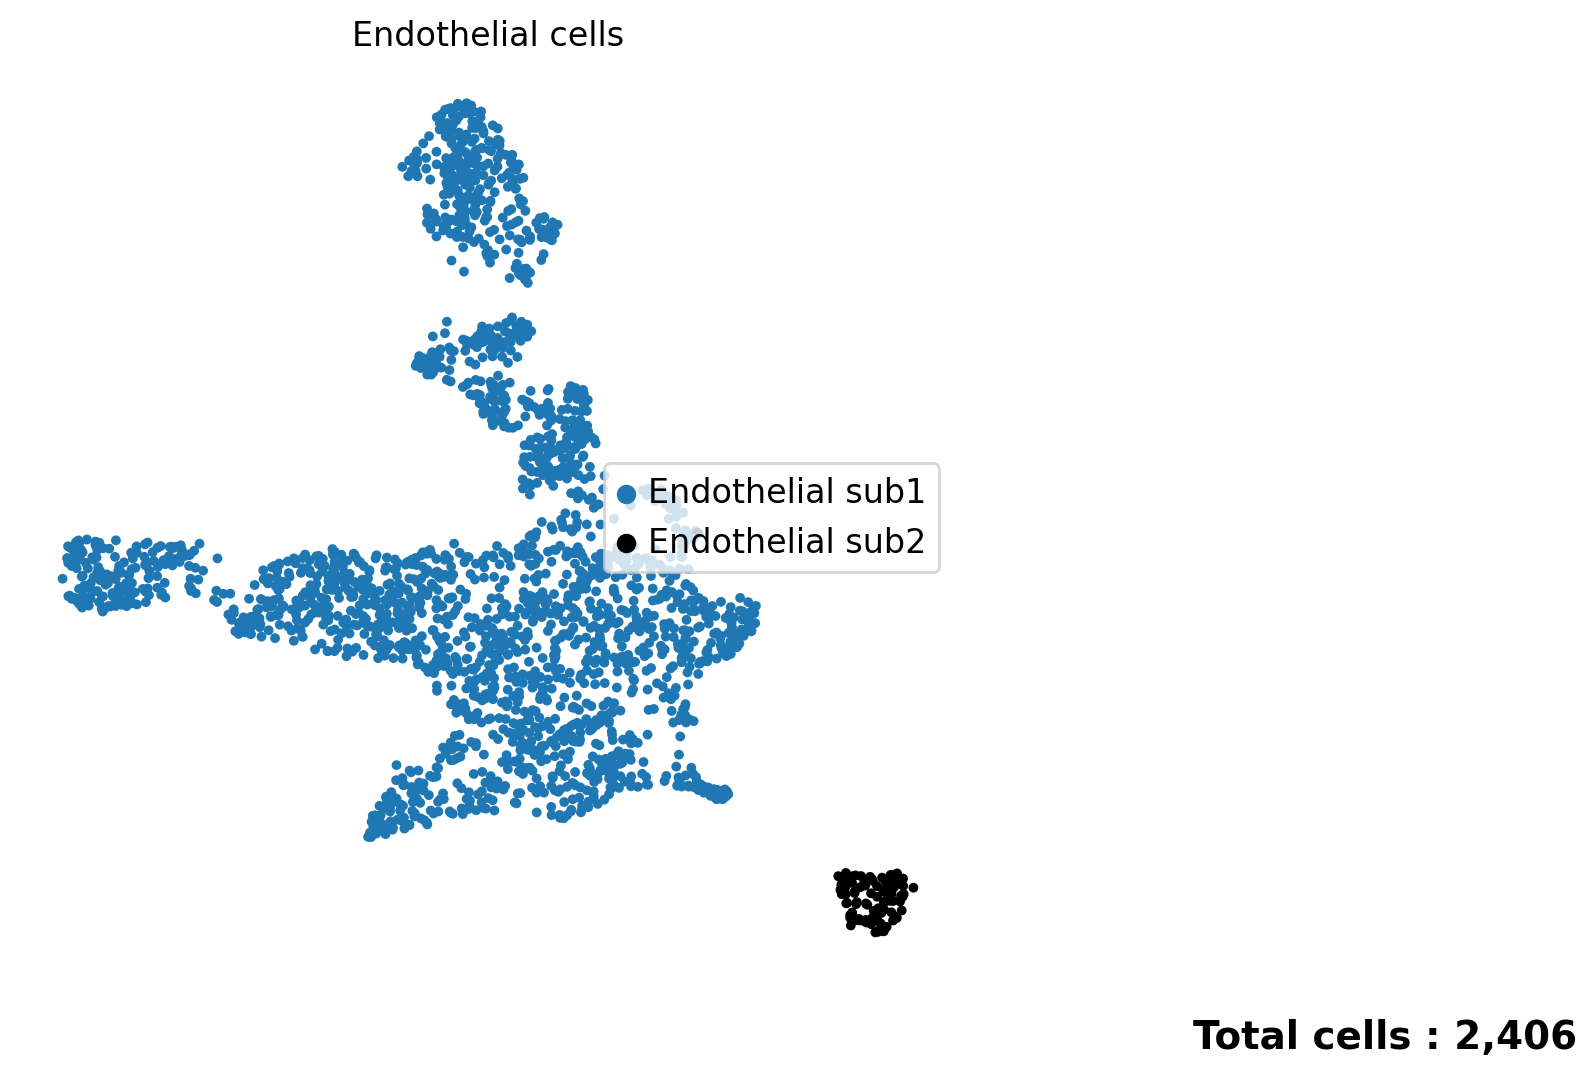

In [12]:
adata.obs.sub_match = pd.Categorical(adata.obs.sub_match, ordered=True, categories=['Endothelial sub1','Endothelial sub2'])
adata.uns['sub_match_colors'] = ["#1F78B4", "#000000"]

fig, ax = plt.subplots(figsize=(6, 6))
ax = sc.pl.umap(
    adata, 
    color='sub_match', 
    legend_loc='right', 
    legend_fontsize=12,
    frameon=False,
    title="Endothelial cells",
    ax=ax,    
    show=False
)
x_start, y_start = -5, -5
ax.text(25, y_start, f"Total cells : {adata.n_obs:,}", 
        fontsize=14, fontweight='bold', ha='right')

plt.savefig("figures/Fig2f_patient_endo_umap_submatch.pdf") 

In [13]:
### treatment composition

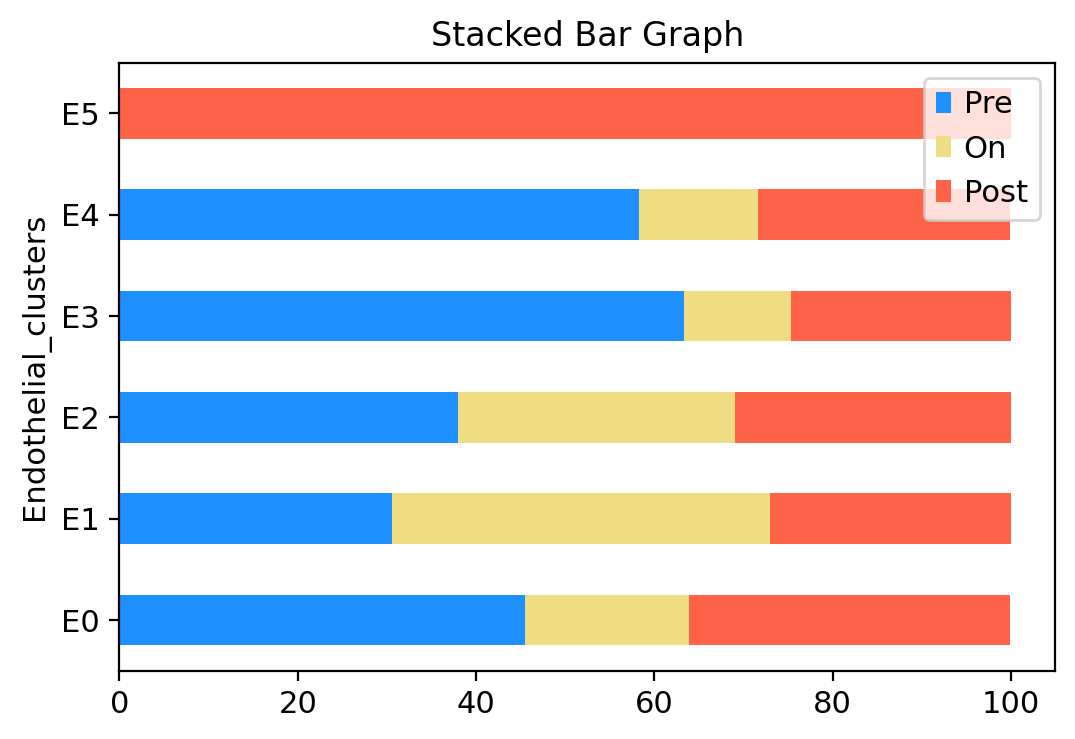

In [14]:
cl_df = pd.crosstab(
    adata.obs['Endothelial_clusters'], 
    adata.obs['condition']
)
cl_df.reset_index(inplace=True)
cl_df = cl_df.rename_axis(None, axis=1)

for idx, row in cl_df.iterrows() :
    pre = row['Pre']
    on = row['On']
    post = row['Post']
    total = pre + on + post
    pre_p = round(pre/total,3) * 100
    on_p = round(on/total,3) * 100
    post_p = round(post/total,3) * 100

    cl_df.loc[idx, 'pre_prop'] = pre_p
    cl_df.loc[idx, 'on_prop'] = on_p
    cl_df.loc[idx, 'post_prop'] = post_p

cl_df_p = cl_df[['Endothelial_clusters','pre_prop','on_prop','post_prop']]
cl_df_p.columns = ['Endothelial_clusters','Pre','On','Post']

fig, ax = plt.subplots(figsize=(6,4))
cl_df_p.plot(
    x = 'Endothelial_clusters',
    kind = 'barh',
    stacked = True,
    title = 'Stacked Bar Graph',
    color = {'Pre' : '#1E90FF', 'On' : '#EEDD82', 'Post' : '#FF6347'},
    mark_right = True,
    ax= ax)

plt.savefig("figures/Fig2h_patient_endo_cluster_prop.pdf")

### RNA velocity
####  Spliced and unspliced read fragments were quantified using tidesurf.

In [15]:
scv.tl.recover_dynamics(adata, n_jobs=5)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata)

recovering dynamics (using 5/80 cores)


  0%|          | 0/545 [00:00<?, ?gene/s]

    finished (0:00:33) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/80 cores)


  0%|          | 0/2406 [00:00<?, ?cells/s]

    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
saving figure to file figures/Fig2f_patient_endo_scvelo_embedding_stream.png


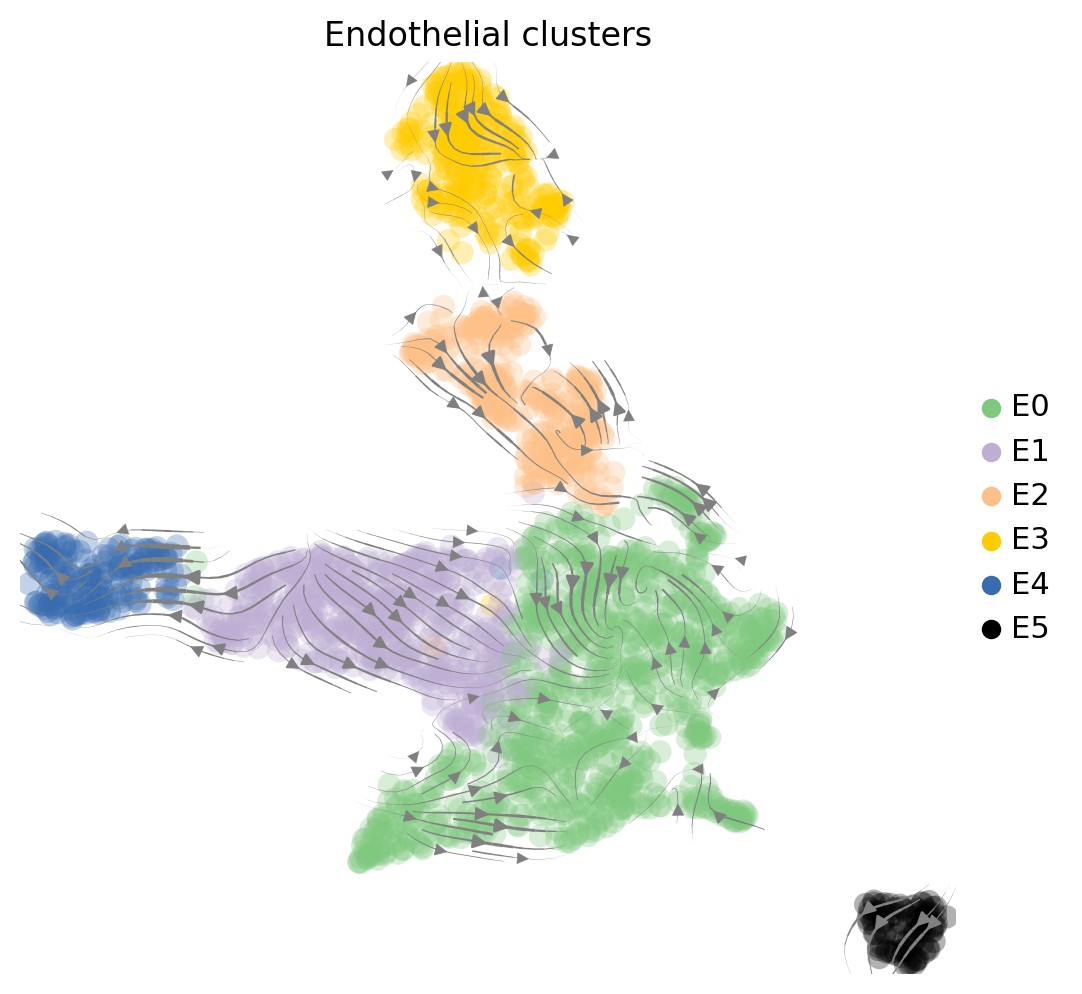

In [16]:
scv.pl.velocity_embedding_stream(adata, basis="umap", color="Endothelial_clusters", density=3,legend_loc = 'right',arrow_color = 'grey',
                                save = 'figures/Fig2f_patient_endo_scvelo_embedding_stream.png',
                                figsize=(6, 6))

In [17]:
adata.write_h5ad('data/2f_h_j/patient_endo_scvelo.h5ad')